# Lab 2 - Clustering text data
# Student: Pleșu Cătălin
# Teacher: Grozavu Nistor

# 1. Import wikipedia data

In [1]:
import pandas as pd
import wikipedia

articles = [
    "Triathlon", "Deep learning", "Data Science", "Artificial intelligence", "European Central Bank", "Bank", "Financial technology",
    "International Monetary Fund", "Basketball", "Swimming"
]
# "Machine Learning" - gives error
# "Tennis"

wiki_lst=[]
title=[]
for article in articles:
	print("loading content: ",article)
	wiki_lst.append(wikipedia.page(article).content)
	title.append(article)
print("examine content")
wiki_lst


loading content:  Triathlon
loading content:  Deep learning
loading content:  Data Science
loading content:  Artificial intelligence
loading content:  European Central Bank
loading content:  Bank
loading content:  Financial technology
loading content:  International Monetary Fund
loading content:  Basketball
loading content:  Swimming
examine content


['A triathlon is an endurance multisport race consisting of swimming, cycling, and running over various distances. Triathletes compete for fastest overall completion time, racing each segment sequentially with the time transitioning between the disciplines included. The word is of Greek origin, from τρεῖς (treîs), \'three\', and ἆθλος (âthlos), \'competition\'.\nThe sport originated in the late 1970s in Southern California as sports clubs and individuals developed the sport. This history has meant that variations of the sport were created and still exist. It also led to other three-stage races using the name triathlon despite not being continuous or not consisting of swim, bike, and run elements.\nTriathletes train to achieve endurance, strength, and speed. The sport requires focused persistent and periodised training for each of the three disciplines, as well as combination workouts and general strength conditioning.\n\n\n== History ==\n\nThe evolution of triathlon as a distinct sport

# 2. Represent each article as a vector

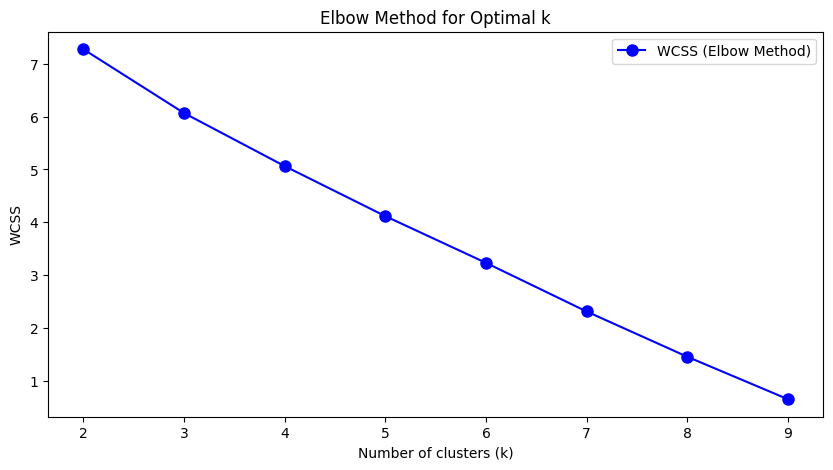

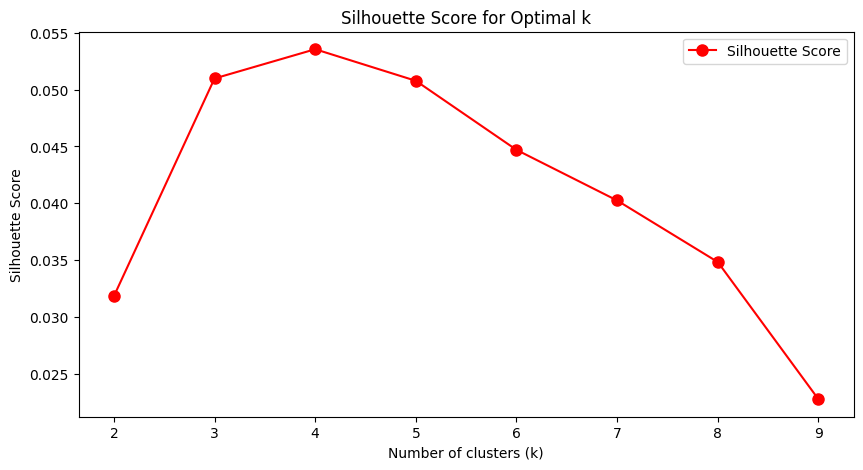

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english", max_features=1000)
X = vectorizer.fit_transform(wiki_lst)

wcss = [] 
silhouette_scores = []

K = range(2, 10) 

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_) 
    silhouette_scores.append(silhouette_score(X, kmeans.labels_)) 

plt.figure(figsize=(10,5))
plt.plot(K, wcss, 'bo-', markersize=8, label="WCSS (Elbow Method)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal k")
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(K, silhouette_scores, 'ro-', markersize=8, label="Silhouette Score")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal k")
plt.legend()
plt.show()


# 4. Evaluate the result

Cluster: 0
Titles:
          Deep learning
Artificial intelligence


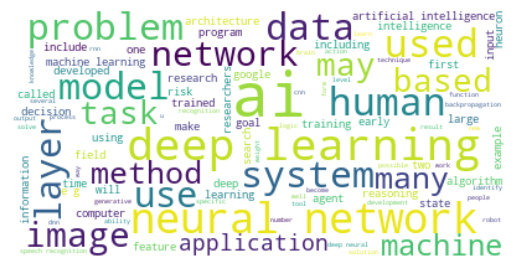

Cluster: 1
Titles:
Swimming


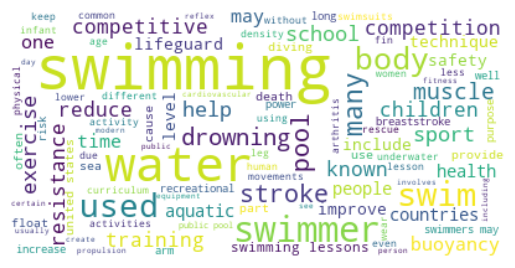

Cluster: 2
Titles:
Financial technology


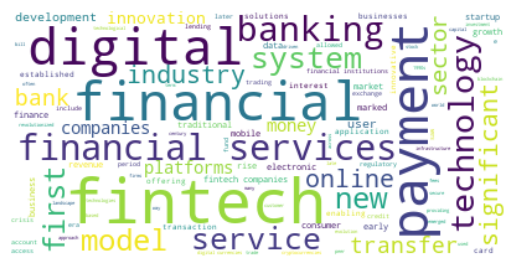

Cluster: 3
Titles:
Basketball


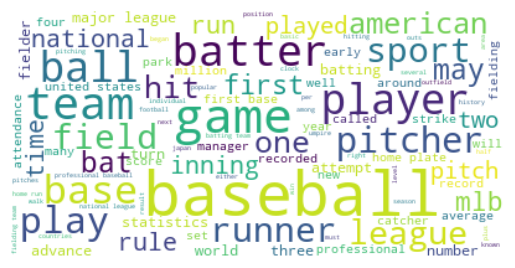

Cluster: 4
Titles:
Data Science


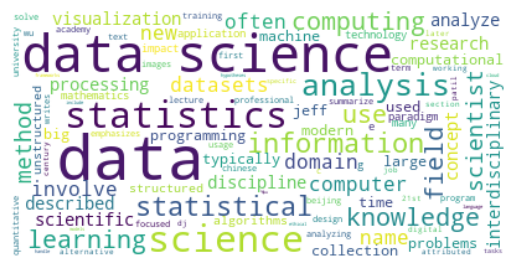

Cluster: 5
Titles:
European Central Bank


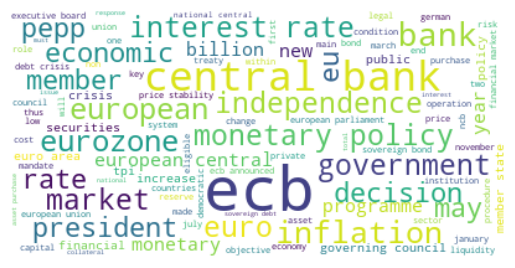

Cluster: 6
Titles:
Bank


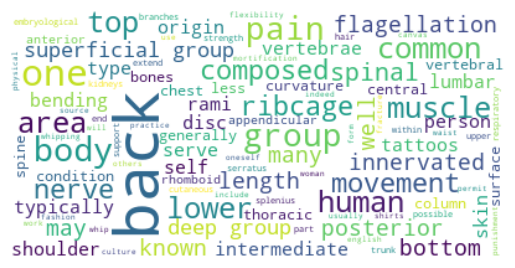

Cluster: 7
Titles:
International Monetary Fund


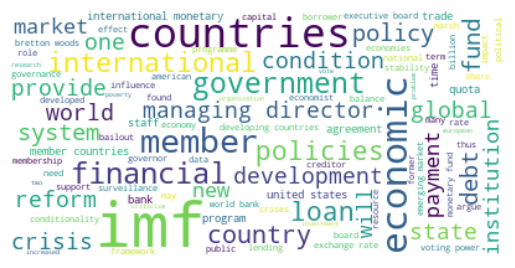

Cluster: 8
Titles:
Triathlon


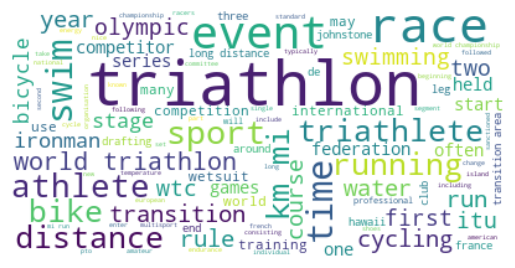

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

result = pd.DataFrame({'cluster': kmeans.labels_, 'wiki': wiki_lst, 'title': title})

for k in range(kmeans.n_clusters):  
    s = result[result.cluster == k]  
    text = s['wiki'].str.cat(sep=' ') 
    text = text.lower()
    
    wordcloud = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(text)
    
    print(f'Cluster: {k}')
    print('Titles:')
    print(s['title'].to_string(index=False)) 

    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()
